# Import

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

from IPython.display import display
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42

# Đọc dữ liệu đã tiền xử lý

In [2]:
# Kế thừa kết quả của notebook "01_eda_preprocess.ipynb"
input_dir = "04_output/02_clean_data"

X_train_model = pd.read_pickle(f"{input_dir}/X_train_model.pkl")   # đã mã hóa
X_test_model = pd.read_pickle(f"{input_dir}/X_test_model.pkl")
y_train = pd.read_pickle(f"{input_dir}/y_train.pkl")
y_test = pd.read_pickle(f"{input_dir}/y_test.pkl")
arm_train = pd.read_pickle(f"{input_dir}/arm_train.pkl")           # đã rời rạc hóa
arm_test = pd.read_pickle(f"{input_dir}/arm_test.pkl")

selected_features = list(X_train_model.columns)

# Thư mục lưu kết quả
output_dir = Path("04_output/03_association_classification_claude")
output_dir.mkdir(parents=True, exist_ok=True)

print("Train:", X_train_model.shape, "| Test:", X_test_model.shape)
print("Số thuộc tính:", len(selected_features))
print("Tỷ lệ tấn công train/test:", round(y_train.mean(), 4), "/", round(y_test.mean(), 4))

arm_train.head()

Train: (1468182, 30) | Test: (367046, 30)
Số thuộc tính: 30
Tỷ lệ tấn công train/test: 0.2406 / 0.2406


,bwd_pkt_len_mean,bwd_pkt_len_tot,pkt_len_max,fwd_pkt_hdr_len_tot,flag_ack,fwd_pkt_len_max,fwd_pkt_len_mean,fwd_subflow_bytes_mean,fwd_pkt_len_tot,bwd_pkt_hdr_len_tot,bwd_tcp_init_win_bytes,iat_max,fwd_iat_max,fwd_tcp_init_win_bytes,bwd_pkt_len_std,bytes_per_s,flag_SYN,bwd_pkt_per_s,bwd_iat_max,fwd_pkt_len_std,fwd_subflow_pkt_mean,down_up_ratio,fwd_pkt_cnt,bwd_pkt_cnt,fwd_iat_std,fwd_non_empty_pkt_cnt,bwd_subflow_pkt_mean,bwd_non_empty_pkt_cnt,fwd_pkt_len_min,bwd_pkt_hdr_len_min
1396392,bwd_pkt_len_mean=Q1,bwd_pkt_len_tot=Q1,pkt_len_max=Q1,fwd_pkt_hdr_len_tot=Q1,flag_ack=Q1,fwd_pkt_len_max=Q1,fwd_pkt_len_mean=Q1,fwd_subflow_bytes_mean=Q2,fwd_pkt_len_tot=Q2,bwd_pkt_hdr_len_tot=Q1,bwd_tcp_init_win_bytes=Q1,iat_max=Q2,fwd_iat_max=Q2,fwd_tcp_init_win_bytes=Q1,bwd_pkt_len_std=Q1,bytes_per_s=Q2,flag_SYN=Q1,bwd_pkt_per_s=Q3,bwd_iat_max=Q2,fwd_pkt_len_std=Q1,fwd_subflow_pkt_mean=Q2,down_up_ratio=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q2,fwd_iat_std=Q1,fwd_non_empty_pkt_cnt=Q2,bwd_subflow_pkt_mean=Q2,bwd_non_empty_pkt_cnt=Q2,fwd_pkt_len_min=Q1,bwd_pkt_hdr_len_min=Q1
248855,bwd_pkt_len_mean=Q1,bwd_pkt_len_tot=Q1,pkt_len_max=Q1,fwd_pkt_hdr_len_tot=Q2,flag_ack=Q1,fwd_pkt_len_max=Q1,fwd_pkt_len_mean=Q1,fwd_subflow_bytes_mean=Q1,fwd_pkt_len_tot=Q1,bwd_pkt_hdr_len_tot=Q2,bwd_tcp_init_win_bytes=Q1,iat_max=Q1,fwd_iat_max=Q1,fwd_tcp_init_win_bytes=Q2,bwd_pkt_len_std=Q1,bytes_per_s=Q1,flag_SYN=Q1,bwd_pkt_per_s=Q4,bwd_iat_max=Q1,fwd_pkt_len_std=Q1,fwd_subflow_pkt_mean=Q1,down_up_ratio=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q1,fwd_iat_std=Q1,fwd_non_empty_pkt_cnt=Q1,bwd_subflow_pkt_mean=Q1,bwd_non_empty_pkt_cnt=Q1,fwd_pkt_len_min=Q1,bwd_pkt_hdr_len_min=Q2
866105,bwd_pkt_len_mean=Q1,bwd_pkt_len_tot=Q2,pkt_len_max=Q1,fwd_pkt_hdr_len_tot=Q2,flag_ack=Q1,fwd_pkt_len_max=Q2,fwd_pkt_len_mean=Q2,fwd_subflow_bytes_mean=Q3,fwd_pkt_len_tot=Q3,bwd_pkt_hdr_len_tot=Q3,bwd_tcp_init_win_bytes=Q1,iat_max=Q2,fwd_iat_max=Q3,fwd_tcp_init_win_bytes=Q1,bwd_pkt_len_std=Q1,bytes_per_s=Q3,flag_SYN=Q1,bwd_pkt_per_s=Q3,bwd_iat_max=Q2,fwd_pkt_len_std=Q1,fwd_subflow_pkt_mean=Q4,down_up_ratio=Q1,fwd_pkt_cnt=Q2,bwd_pkt_cnt=Q3,fwd_iat_std=Q1,fwd_non_empty_pkt_cnt=Q4,bwd_subflow_pkt_mean=Q4,bwd_non_empty_pkt_cnt=Q4,fwd_pkt_len_min=Q1,bwd_pkt_hdr_len_min=Q1
253743,bwd_pkt_len_mean=Q1,bwd_pkt_len_tot=Q1,pkt_len_max=Q1,fwd_pkt_hdr_len_tot=Q2,flag_ack=Q1,fwd_pkt_len_max=Q1,fwd_pkt_len_mean=Q1,fwd_subflow_bytes_mean=Q1,fwd_pkt_len_tot=Q1,bwd_pkt_hdr_len_tot=Q2,bwd_tcp_init_win_bytes=Q1,iat_max=Q1,fwd_iat_max=Q1,fwd_tcp_init_win_bytes=Q2,bwd_pkt_len_std=Q1,bytes_per_s=Q1,flag_SYN=Q1,bwd_pkt_per_s=Q4,bwd_iat_max=Q1,fwd_pkt_len_std=Q1,fwd_subflow_pkt_mean=Q1,down_up_ratio=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q1,fwd_iat_std=Q1,fwd_non_empty_pkt_cnt=Q1,bwd_subflow_pkt_mean=Q1,bwd_non_empty_pkt_cnt=Q1,fwd_pkt_len_min=Q1,bwd_pkt_hdr_len_min=Q2
1784461,bwd_pkt_len_mean=Q2,bwd_pkt_len_tot=Q2,pkt_len_max=Q2,fwd_pkt_hdr_len_tot=Q1,flag_ack=Q1,fwd_pkt_len_max=Q2,fwd_pkt_len_mean=Q2,fwd_subflow_bytes_mean=Q3,fwd_pkt_len_tot=Q3,bwd_pkt_hdr_len_tot=Q1,bwd_tcp_init_win_bytes=Q1,iat_max=Q1,fwd_iat_max=Q2,fwd_tcp_init_win_bytes=Q1,bwd_pkt_len_std=Q1,bytes_per_s=Q4,flag_SYN=Q1,bwd_pkt_per_s=Q4,bwd_iat_max=Q1,fwd_pkt_len_std=Q1,fwd_subflow_pkt_mean=Q2,down_up_ratio=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q2,fwd_iat_std=Q1,fwd_non_empty_pkt_cnt=Q2,bwd_subflow_pkt_mean=Q2,bwd_non_empty_pkt_cnt=Q2,fwd_pkt_len_min=Q2,bwd_pkt_hdr_len_min=Q1


# Khai phá luật kết hợp

## Chuẩn bị dữ liệu giao dịch
Mỗi dòng dữ liệu là một giao dịch, mỗi item có dạng `tên_cột=giá_trị`.
Thêm item nhãn `label=attack` / `label=benign` để luật có thể kết luận về nhãn.

Hai thuật toán cần hai dạng dữ liệu khác nhau:
- Apriori: bảng one-hot để đếm support bằng phép toán ma trận
- FP-Growth: danh sách giao dịch để đưa vào cây FP-tree

In [3]:
# Chỉ lấy 10 thuộc tính đầu (đã xếp theo Mutual Information ở notebook 01)
arm_cols = selected_features[:10]

# Lấy mẫu 50.000 giao dịch để khai phá luật cho nhanh, giữ nguyên tỷ lệ nhãn
mining_idx, _ = train_test_split(
    y_train.index,
    train_size=50_000,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

# Bảng item: thuộc tính đã rời rạc hóa + item nhãn
df_items = arm_train.loc[mining_idx, arm_cols].astype(str)
df_items["label"] = np.where(
    y_train.loc[mining_idx].eq(1),
    "label=attack",
    "label=benign"
)

basket = pd.get_dummies(df_items, prefix="", prefix_sep="")   # cho Apriori
transactions = df_items.to_numpy().tolist()                   # cho FP-Growth

# Dạng dọc cho CHARM: mỗi item -> tập id các giao dịch có chứa item đó
tidsets = defaultdict(set)
for tid, items in enumerate(transactions):
    for item in items:
        tidsets[item].add(tid)
tidsets = dict(tidsets)

print("Thuộc tính dùng khai phá:", arm_cols)
print("Bảng one-hot:", basket.shape, "| Số giao dịch:", len(transactions))
print("Số item khác nhau:", len(tidsets))

basket.head()

Thuộc tính dùng khai phá: ['bwd_pkt_len_mean', 'bwd_pkt_len_tot', 'pkt_len_max', 'fwd_pkt_hdr_len_tot', 'flag_ack', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_subflow_bytes_mean', 'fwd_pkt_len_tot', 'bwd_pkt_hdr_len_tot']
Bảng one-hot: (50000, 41) | Số giao dịch: 50000
Số item khác nhau: 41


,bwd_pkt_len_mean=Q1,bwd_pkt_len_mean=Q2,bwd_pkt_len_mean=Q3,bwd_pkt_len_mean=Q4,bwd_pkt_len_tot=Q1,bwd_pkt_len_tot=Q2,bwd_pkt_len_tot=Q3,bwd_pkt_len_tot=Q4,pkt_len_max=Q1,pkt_len_max=Q2,pkt_len_max=Q3,pkt_len_max=Q4,fwd_pkt_hdr_len_tot=Q1,fwd_pkt_hdr_len_tot=Q2,fwd_pkt_hdr_len_tot=Q3,fwd_pkt_hdr_len_tot=Q4,flag_ack=Q1,flag_ack=Q2,flag_ack=Q3,fwd_pkt_len_max=Q1,fwd_pkt_len_max=Q2,fwd_pkt_len_max=Q3,fwd_pkt_len_max=Q4,fwd_pkt_len_mean=Q1,fwd_pkt_len_mean=Q2,fwd_pkt_len_mean=Q3,fwd_pkt_len_mean=Q4,fwd_subflow_bytes_mean=Q1,fwd_subflow_bytes_mean=Q2,fwd_subflow_bytes_mean=Q3,fwd_subflow_bytes_mean=Q4,fwd_pkt_len_tot=Q1,fwd_pkt_len_tot=Q2,fwd_pkt_len_tot=Q3,fwd_pkt_len_tot=Q4,bwd_pkt_hdr_len_tot=Q1,bwd_pkt_hdr_len_tot=Q2,bwd_pkt_hdr_len_tot=Q3,bwd_pkt_hdr_len_tot=Q4,label=attack,label=benign
368789,True,False,False,False,True,False,False,False,True,False,False,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,True,False,False,True,False
1787465,False,True,False,False,False,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,False,True,False,False,False,True,False,False,True,False,False,False,False,True
859907,False,True,False,False,True,False,False,False,False,True,False,False,True,False,False,False,True,False,False,False,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,True
231425,True,False,False,False,True,False,False,False,True,False,False,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,True,False,False,True,False
929337,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,True,False,False,True,False,False,False,True,False,False,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,True


## Ngưỡng dùng chung cho cả ba phương pháp
Ba phương pháp dùng **cùng** min_support, min_confidence và tiền đề tối đa 2 item
để việc so sánh được công bằng.

In [4]:
MIN_SUPPORT = 0.05      # tập mục phải xuất hiện ở ít nhất 5% giao dịch
MIN_CONFIDENCE = 0.60   # luật phải đúng ít nhất 60% số lần
MAX_LEN = 3             # tập mục tối đa 3 item (tiền đề tối đa 2 item)
TARGET = "label=attack"

print("min_support:", MIN_SUPPORT, "| min_confidence:", MIN_CONFIDENCE, "| max_len:", MAX_LEN)

min_support: 0.05 | min_confidence: 0.6 | max_len: 3


## Phương pháp 1 - Apriori
Duyệt theo từng mức: tìm tập 1 item phổ biến, ghép thành ứng viên 2 item, rồi 3 item.
Trước khi đếm, tỉa ứng viên theo tính chất Apriori: mọi tập con của tập phổ biến cũng phải phổ biến.

In [5]:
def apriori(basket, min_support, max_len):
    values = basket.to_numpy()
    columns = list(basket.columns)
    frequent = {}

    # Mức 1: đếm từng item
    level = []
    for i in range(len(columns)):
        support = values[:, i].mean()
        if support >= min_support:
            level.append((i,))
            frequent[frozenset([columns[i]])] = support

    # Mức 2 trở lên: ghép ứng viên từ các item còn lại của mức trước
    k = 2
    while level and k <= max_len:
        level_set = set(level)
        items_left = sorted({i for item_set in level for i in item_set})
        new_level = []

        for candidate in combinations(items_left, k):
            # Tỉa: mọi tập con (k-1) item của ứng viên phải phổ biến
            if any(sub not in level_set for sub in combinations(candidate, k - 1)):
                continue

            support = values[:, candidate].all(axis=1).mean()
            if support >= min_support:
                new_level.append(candidate)
                frequent[frozenset(columns[i] for i in candidate)] = support

        level = new_level
        k += 1

    return frequent


freq_apriori = apriori(basket, MIN_SUPPORT, MAX_LEN)

print("Số tập mục phổ biến - Apriori:", len(freq_apriori))

Số tập mục phổ biến - Apriori: 1592


## Phương pháp 2 - FP-Growth
Nén dữ liệu vào cây FP-tree (các giao dịch có phần đầu giống nhau dùng chung nhánh),
sau đó khai phá đệ quy trên cây điều kiện của từng item, không cần sinh ứng viên.

In [6]:
class FPNode:
    def __init__(self, item, parent):
        self.item = item
        self.parent = parent
        self.count = 0
        self.children = {}


def build_fp_tree(rows, min_count):
    # rows: danh sách (các item, số lần lặp)
    counts = Counter()
    for items, weight in rows:
        for item in items:
            counts[item] += weight
    frequent_items = {item for item in counts if counts[item] >= min_count}

    root = FPNode(None, None)
    header = defaultdict(list)

    for items, weight in rows:
        # Bỏ item không phổ biến, sắp xếp theo tần suất giảm dần rồi thêm vào cây
        ordered = sorted(
            (item for item in items if item in frequent_items),
            key=lambda item: (-counts[item], item)
        )

        node = root
        for item in ordered:
            if item not in node.children:
                node.children[item] = FPNode(item, node)
                header[item].append(node.children[item])
            node = node.children[item]
            node.count += weight

    return header, counts, frequent_items


def fp_growth(transactions, min_support, max_len):
    n = len(transactions)
    min_count = min_support * n
    frequent = {}

    def mine(rows, prefix):
        header, counts, frequent_items = build_fp_tree(rows, min_count)

        for item in sorted(frequent_items):
            pattern = prefix | {item}
            frequent[frozenset(pattern)] = counts[item] / n

            if len(pattern) >= max_len:
                continue

            # Lấy các đường đi chứa item để tạo dữ liệu điều kiện
            conditional = []
            for node in header[item]:
                path = []
                parent = node.parent
                while parent is not None and parent.item is not None:
                    path.append(parent.item)
                    parent = parent.parent
                if path:
                    conditional.append((path, node.count))

            if conditional:
                mine(conditional, pattern)

    mine([(items, 1) for items in transactions], frozenset())
    return frequent


freq_fp = fp_growth(transactions, MIN_SUPPORT, MAX_LEN)

print("Số tập mục phổ biến - FP-Growth:", len(freq_fp))

Số tập mục phổ biến - FP-Growth: 1592


## Phương pháp 3 - CHARM
CHARM chỉ tìm **tập mục đóng**: tập mục mà mọi tập lớn hơn chứa nó đều có support nhỏ hơn.
Dùng dạng dọc (mỗi item ứng với tập id giao dịch), giao các tập id để tính support
và lấy bao đóng để bỏ các tập mục dư thừa.

In [7]:
def charm(tidsets, n, min_support):
    min_count = min_support * n
    frequent_tidsets = {
        item: tids for item, tids in tidsets.items() if len(tids) >= min_count
    }

    # Xét item ít phổ biến trước cho nhánh tìm kiếm hẹp lại nhanh
    items_sorted = sorted(
        frequent_tidsets,
        key=lambda item: (len(frequent_tidsets[item]), item)
    )
    closed = {}

    def search(prefix, prefix_tids, candidates):
        # Bao đóng: thêm mọi item có mặt ở tất cả giao dịch của prefix
        if prefix:
            closure = set(prefix)
            for item, tids in frequent_tidsets.items():
                if prefix_tids <= tids:
                    closure.add(item)
            closed[frozenset(closure)] = len(prefix_tids) / n

        for i, item in enumerate(candidates):
            tids = prefix_tids & frequent_tidsets[item]
            if len(tids) >= min_count:
                search(prefix | {item}, tids, candidates[i + 1:])

    search(frozenset(), set(range(n)), items_sorted)
    return closed


freq_charm = charm(tidsets, len(transactions), MIN_SUPPORT)

print("Số tập mục đóng - CHARM:", len(freq_charm))
print("Trong đó tập mục có tối đa", MAX_LEN, "item:",
      sum(1 for itemset in freq_charm if len(itemset) <= MAX_LEN))

Số tập mục đóng - CHARM: 2842
Trong đó tập mục có tối đa 3 item: 829


## Kiểm tra ba thuật toán
- Apriori và FP-Growth chỉ khác **cách đi tìm** nên cùng ngưỡng phải ra cùng tập mục và cùng support
- CHARM giữ ít tập mục hơn nhưng không mất thông tin: support của mọi tập mục phổ biến
  bằng support lớn nhất trong các tập đóng chứa nó

Đây cũng là cách kiểm tra code ba thuật toán có đúng hay không.

In [8]:
same_itemsets = set(freq_apriori) == set(freq_fp)
max_diff = max(abs(freq_apriori[s] - freq_fp[s]) for s in freq_apriori) if same_itemsets else None

print("Apriori và FP-Growth:")
print("   - Số tập mục:", len(freq_apriori), "/", len(freq_fp))
print("   - Cùng tập mục phổ biến:", same_itemsets)
print("   - Chênh lệch support lớn nhất:", max_diff)

# Suy lại support của từng tập mục phổ biến từ các tập đóng của CHARM
closed_items = list(freq_charm.items())
max_diff_charm = 0

for itemset, support in freq_apriori.items():
    support_from_closed = max(s for c, s in closed_items if itemset <= c)
    max_diff_charm = max(max_diff_charm, abs(support_from_closed - support))

n_closed_small = sum(1 for itemset in freq_charm if len(itemset) <= MAX_LEN)

print("CHARM:")
print("   - Chỉ cần", n_closed_small, "tập đóng để suy ra support của",
      len(freq_apriori), "tập phổ biến")
print("   - Chênh lệch support lớn nhất khi suy lại:", max_diff_charm)

Apriori và FP-Growth:
   - Số tập mục: 1592 / 1592
   - Cùng tập mục phổ biến: True
   - Chênh lệch support lớn nhất: 0.0
CHARM:
   - Chỉ cần 829 tập đóng để suy ra support của 1592 tập phổ biến
   - Chênh lệch support lớn nhất khi suy lại: 0


## Sinh luật kết luận là tấn công
Chỉ giữ luật dạng `điều kiện -> label=attack` có confidence >= 0.60 và lift > 1.
- coverage (độ phủ) = tỷ lệ giao dịch thỏa điều kiện của luật
- confidence = trong số giao dịch thỏa điều kiện, bao nhiêu phần là tấn công
- lift > 1 nghĩa là luật tốt hơn đoán theo tỷ lệ tấn công chung

In [9]:
def get_rules(frequent, target, min_confidence):
    support_target = frequent[frozenset([target])]
    rows = []

    for itemset, support in frequent.items():
        if target not in itemset or len(itemset) < 2:
            continue

        antecedent = itemset - {target}
        coverage = frequent[antecedent]
        confidence = support / coverage

        if confidence >= min_confidence and confidence > support_target:
            rows.append({
                "Tiền đề": antecedent,
                "Coverage": coverage,
                "Support": support,
                "Confidence": confidence,
                "Lift": confidence / support_target,
            })

    rules = pd.DataFrame(rows)
    # Thầy nhấn mạnh độ phủ nên ưu tiên luật phủ nhiều giao dịch
    rules = rules.sort_values(["Coverage", "Confidence"], ascending=False)
    return rules.reset_index(drop=True)


rules_apriori = get_rules(freq_apriori, TARGET, MIN_CONFIDENCE)
rules_fp = get_rules(freq_fp, TARGET, MIN_CONFIDENCE)

print("Số luật tấn công - Apriori:", len(rules_apriori))
print("Số luật tấn công - FP-Growth:", len(rules_fp))

rules_apriori.head()

Số luật tấn công - Apriori: 78
Số luật tấn công - FP-Growth: 78


,Tiền đề,Coverage,Support,Confidence,Lift
0,frozenset({fwd_pkt_hdr_len_tot=Q3}),0.23108,0.16794,0.726761,3.020118
1,"frozenset({bwd_pkt_len_tot=Q4, bwd_pkt_len_mea...",0.21712,0.14088,0.648858,2.696384
2,"frozenset({fwd_pkt_len_max=Q1, fwd_pkt_len_mea...",0.21404,0.14572,0.680807,2.829153
3,"frozenset({bwd_pkt_len_mean=Q4, pkt_len_max=Q4})",0.21138,0.14190,0.671303,2.789656
4,"frozenset({bwd_pkt_len_tot=Q4, pkt_len_max=Q4})",0.20960,0.14086,0.672042,2.792728


### Luật từ CHARM
Vì CHARM chỉ giữ tập mục đóng nên luật sinh ra là **luật không dư thừa**: số luật ít hơn
nhiều nhưng không bỏ sót thông tin. Độ phủ của tiền đề được suy lại từ các tập đóng
(đã kiểm chứng ở trên là suy lại đúng).

In [10]:
def support_from_closed(closed, itemset):
    # Support của một tập mục = support lớn nhất trong các tập đóng chứa nó
    return max(s for c, s in closed.items() if itemset <= c)


def get_rules_closed(closed, target, min_confidence, max_antecedent=2):
    support_target = support_from_closed(closed, frozenset([target]))
    rows = []
    seen = set()

    for itemset, support in closed.items():
        if target not in itemset:
            continue

        antecedent = itemset - {target}

        if not 1 <= len(antecedent) <= max_antecedent or antecedent in seen:
            continue
        seen.add(antecedent)

        coverage = support_from_closed(closed, antecedent)
        confidence = support / coverage

        if confidence >= min_confidence and confidence > support_target:
            rows.append({
                "Tiền đề": antecedent,
                "Coverage": coverage,
                "Support": support,
                "Confidence": confidence,
                "Lift": confidence / support_target,
            })

    rules = pd.DataFrame(rows)
    rules = rules.sort_values(["Coverage", "Confidence"], ascending=False)
    return rules.reset_index(drop=True)


rules_charm = get_rules_closed(freq_charm, TARGET, MIN_CONFIDENCE)

print("Số luật tấn công - CHARM:", len(rules_charm))

rules_charm.head()

Số luật tấn công - CHARM: 18


,Tiền đề,Coverage,Support,Confidence,Lift
0,frozenset({fwd_pkt_hdr_len_tot=Q3}),0.23108,0.16794,0.726761,3.020118
1,"frozenset({bwd_pkt_len_tot=Q4, bwd_pkt_len_mea...",0.21712,0.14088,0.648858,2.696384
2,"frozenset({bwd_pkt_len_mean=Q4, pkt_len_max=Q4})",0.21138,0.14190,0.671303,2.789656
3,"frozenset({fwd_pkt_len_mean=Q1, fwd_subflow_by...",0.19278,0.14576,0.756095,3.142017
4,frozenset({flag_ack=Q2}),0.17774,0.12072,0.679194,2.822450


## Chọn 3 luật cho mỗi phương pháp
Thầy đánh giá theo **độ phủ chung của ba luật** nên chọn luật theo đúng tiêu chí đó:
mỗi lượt lấy luật phủ thêm được nhiều giao dịch **mới** nhất (giao dịch đã được luật
trước phủ rồi thì không tính lại). Cả ba phương pháp dùng chung một cách chọn này.

In [11]:
def rule_tids(antecedent, tidsets):
    # Tập id giao dịch thỏa điều kiện của luật
    tids = None
    for item in antecedent:
        tids = set(tidsets[item]) if tids is None else tids & tidsets[item]
    return tids


def pick_3_rules(rules, tidsets):
    chosen = []
    covered = set()
    remaining = list(rules.index)

    while remaining and len(chosen) < 3:
        best = None
        best_new = -1
        best_tids = None

        # Tìm luật phủ thêm được nhiều giao dịch mới nhất
        for i in remaining:
            tids = rule_tids(rules.loc[i, "Tiền đề"], tidsets)
            n_new = len(tids - covered)
            if n_new > best_new:
                best = i
                best_new = n_new
                best_tids = tids

        chosen.append(best)
        covered = covered | best_tids
        remaining.remove(best)

    if len(chosen) < 3:
        raise ValueError("Chưa đủ 3 luật, cần giảm MIN_SUPPORT hoặc MIN_CONFIDENCE")

    return rules.loc[chosen].reset_index(drop=True)


rule_3_apriori = pick_3_rules(rules_apriori, tidsets)
rule_3_fp = pick_3_rules(rules_fp, tidsets)
rule_3_charm = pick_3_rules(rules_charm, tidsets)

print("Đã chọn 3 luật cho mỗi phương pháp")

Đã chọn 3 luật cho mỗi phương pháp


In [12]:
# Bảng 6 luật để trình bày
def show_rules(rules, method):
    return pd.DataFrame({
        "Phương pháp": method,
        "Luật": [f"Rule_{i + 1}" for i in range(len(rules))],
        "Tiền đề (IF)": rules["Tiền đề"].apply(
            lambda items: " & ".join(sorted(items))
        ),
        "Kết luận (THEN)": TARGET,
        "Coverage": rules["Coverage"].round(4),
        "Support": rules["Support"].round(4),
        "Confidence": rules["Confidence"].round(4),
        "Lift": rules["Lift"].round(4),
    })


rules_table = pd.concat(
    [
        show_rules(rule_3_apriori, "Apriori"),
        show_rules(rule_3_fp, "FP-Growth"),
        show_rules(rule_3_charm, "CHARM"),
    ],
    ignore_index=True
)

rules_table.to_csv(output_dir / "01_rules.csv", index=False)

rules_table

,Phương pháp,Luật,Tiền đề (IF),Kết luận (THEN),Coverage,Support,Confidence,Lift
0,Apriori,Rule_1,fwd_pkt_hdr_len_tot=Q3,label=attack,0.2311,0.1679,0.7268,3.0201
1,Apriori,Rule_2,bwd_pkt_len_mean=Q4 & bwd_pkt_len_tot=Q4,label=attack,0.2171,0.1409,0.6489,2.6964
2,Apriori,Rule_3,fwd_pkt_len_max=Q1 & fwd_pkt_len_mean=Q1,label=attack,0.2140,0.1457,0.6808,2.8292
3,FP-Growth,Rule_1,fwd_pkt_hdr_len_tot=Q3,label=attack,0.2311,0.1679,0.7268,3.0201
4,FP-Growth,Rule_2,bwd_pkt_len_mean=Q4 & bwd_pkt_len_tot=Q4,label=attack,0.2171,0.1409,0.6489,2.6964
5,FP-Growth,Rule_3,fwd_pkt_len_max=Q1 & fwd_pkt_len_mean=Q1,label=attack,0.2140,0.1457,0.6808,2.8292
6,CHARM,Rule_1,fwd_pkt_hdr_len_tot=Q3,label=attack,0.2311,0.1679,0.7268,3.0201
7,CHARM,Rule_2,bwd_pkt_len_mean=Q4 & bwd_pkt_len_tot=Q4,label=attack,0.2171,0.1409,0.6489,2.6964
8,CHARM,Rule_3,fwd_pkt_len_mean=Q1 & fwd_subflow_bytes_mean=Q1,label=attack,0.1928,0.1458,0.7561,3.1420


# So sánh hai phương pháp bằng độ phủ
Độ phủ tính trên **toàn bộ tập train** (không chỉ 50.000 giao dịch đã khai phá).
Độ phủ chung tính theo số giao dịch thỏa **ít nhất một** trong ba luật, không cộng dồn
ba tỷ lệ vì các luật có thể phủ trùng giao dịch.

In [13]:
# Đánh dấu 1/0: giao dịch có thỏa điều kiện của từng luật hay không
def rule_flags(df_items, rules):
    flags = pd.DataFrame(index=df_items.index)

    for i in range(len(rules)):
        match = pd.Series(True, index=df_items.index)
        for item in rules.loc[i, "Tiền đề"]:
            col = item.split("=")[0]
            match = match & df_items[col].astype(str).eq(item)
        flags[f"Rule_{i + 1}"] = match.astype(int)

    return flags


flags_apriori = rule_flags(arm_train, rule_3_apriori)
flags_fp = rule_flags(arm_train, rule_3_fp)
flags_charm = rule_flags(arm_train, rule_3_charm)

print("Bảng cờ luật:", flags_apriori.shape, flags_fp.shape, flags_charm.shape)

flags_apriori.head()

Bảng cờ luật: (1468182, 3) (1468182, 3) (1468182, 3)


,Rule_1,Rule_2,Rule_3
1396392,0,0,1
248855,0,0,1
866105,0,0,0
253743,0,0,1
1784461,0,0,0


In [14]:
def coverage_list(flags):
    return [
        3,
        round(100 * flags["Rule_1"].mean(), 2),
        round(100 * flags["Rule_2"].mean(), 2),
        round(100 * flags["Rule_3"].mean(), 2),
        round(100 * flags.any(axis=1).mean(), 2),
    ]


coverage_table = pd.DataFrame({
    "Tiêu chí": [
        "Số luật chọn",
        "Độ phủ luật 1 (%)",
        "Độ phủ luật 2 (%)",
        "Độ phủ luật 3 (%)",
        "Độ phủ chung của 3 luật (%)",
    ],
    "Apriori": coverage_list(flags_apriori),
    "FP-Growth": coverage_list(flags_fp),
    "CHARM": coverage_list(flags_charm),
})

coverage_table.to_csv(output_dir / "02_rule_coverage.csv", index=False)

coverage_table

,Tiêu chí,Apriori,FP-Growth,CHARM
0,Số luật chọn,3.00,3.00,3.00
1,Độ phủ luật 1 (%),23.16,23.16,23.16
2,Độ phủ luật 2 (%),21.79,21.79,21.79
3,Độ phủ luật 3 (%),21.62,21.62,19.42
4,Độ phủ chung của 3 luật (%),42.01,42.01,39.57


### Nhận xét về độ phủ
- **Apriori và FP-Growth**: cùng ngưỡng nên tìm ra cùng tập mục phổ biến, dẫn tới cùng
  tập luật và **độ phủ bằng nhau**. Hai thuật toán khác nhau ở cách đi tìm (Apriori sinh
  và đếm ứng viên theo từng mức, FP-Growth nén dữ liệu vào cây) chứ không khác ở tập luật.
- **CHARM**: chỉ giữ tập mục đóng nên tập luật của CHARM là **tập con** của tập luật
  Apriori. Vì vậy khi chọn luật theo độ phủ, CHARM **không thể cao hơn** Apriori -
  cùng lắm là bằng. Điểm mạnh của CHARM không nằm ở độ phủ mà ở chỗ sinh ít luật hơn
  hẳn mà vẫn giữ đủ thông tin.

Nếu một báo cáo cho ra độ phủ của CHARM **cao hơn** Apriori thì nguyên nhân thường là
tiêu chí chọn luật không thuần độ phủ (ví dụ chấm điểm theo độ phủ nhân với confidence
và lift). Khi đó Apriori có nhiều luật confidence cao nhưng phủ hẹp nên bị tiêu chí kéo
về phía các luật hẹp, còn CHARM không có sẵn các luật đó nên buộc phải lấy luật phủ rộng.
Độ phủ cao hơn trong trường hợp đó đến từ cách chấm điểm, không phải do thuật toán tốt hơn.

In [15]:
# Hai bộ luật có giống nhau không
def same_rules(rules_a, rules_b):
    return (
        [sorted(items) for items in rules_a["Tiền đề"]]
        == [sorted(items) for items in rules_b["Tiền đề"]]
    )


coverage_all = {
    "Apriori": flags_apriori.any(axis=1).mean(),
    "FP-Growth": flags_fp.any(axis=1).mean(),
    "CHARM": flags_charm.any(axis=1).mean(),
}

print("3 luật Apriori giống FP-Growth:", same_rules(rule_3_apriori, rule_3_fp))
print("3 luật Apriori giống CHARM:", same_rules(rule_3_apriori, rule_3_charm))

for method, coverage in coverage_all.items():
    print("Độ phủ chung -", method, ":", round(100 * coverage, 2), "%")

# Dùng luật của phương pháp có độ phủ chung cao nhất để tạo thuộc tính cho D1
chosen_method = max(coverage_all, key=coverage_all.get)
rule_3_all = {
    "Apriori": rule_3_apriori,
    "FP-Growth": rule_3_fp,
    "CHARM": rule_3_charm,
}
chosen_rules = rule_3_all[chosen_method]

print("=> Phương pháp dùng để tạo thuộc tính mới:", chosen_method)

3 luật Apriori giống FP-Growth: True
3 luật Apriori giống CHARM: False
Độ phủ chung - Apriori : 42.01 %
Độ phủ chung - FP-Growth : 42.01 %
Độ phủ chung - CHARM : 39.57 %
=> Phương pháp dùng để tạo thuộc tính mới: Apriori


# Tạo 3 thuộc tính mới từ luật
- **D0**: thuộc tính gốc sau tiền xử lý
- **D1**: D0 + 3 thuộc tính nhị phân `Rule_1`, `Rule_2`, `Rule_3` của phương pháp có độ phủ cao nhất
- **D2**: D0 + 3 thuộc tính nhị phân của CHARM (ba luật khác nên để so sánh thêm)

Giá trị 1 nghĩa là dòng dữ liệu thỏa điều kiện của luật, 0 là không thỏa.

In [16]:
# D0 - dữ liệu gốc sau tiền xử lý
X_train_d0 = X_train_model.copy()
X_test_d0 = X_test_model.copy()

# D1 - thêm 3 thuộc tính từ phương pháp có độ phủ cao nhất
X_train_d1 = X_train_d0.join(rule_flags(arm_train, chosen_rules))
X_test_d1 = X_test_d0.join(rule_flags(arm_test, chosen_rules))

# D2 - thêm 3 thuộc tính từ CHARM
X_train_d2 = X_train_d0.join(rule_flags(arm_train, rule_3_charm))
X_test_d2 = X_test_d0.join(rule_flags(arm_test, rule_3_charm))

print("D1 dùng luật của:", chosen_method, "| D2 dùng luật của: CHARM")
print("D0:", X_train_d0.shape, X_test_d0.shape)
print("D1:", X_train_d1.shape, X_test_d1.shape)
print("D2:", X_train_d2.shape, X_test_d2.shape)

X_train_d1[["Rule_1", "Rule_2", "Rule_3"]].head()

D1 dùng luật của: Apriori | D2 dùng luật của: CHARM
D0: (1468182, 30) (367046, 30)
D1: (1468182, 33) (367046, 33)
D2: (1468182, 33) (367046, 33)


,Rule_1,Rule_2,Rule_3
1396392,0,0,1
248855,0,0,1
866105,0,0,0
253743,0,0,1
1784461,0,0,0


In [17]:
# Kiểm tra nhanh 3 thuộc tính mới trên tập train
rule_check = []

for col in ["Rule_1", "Rule_2", "Rule_3"]:
    mask = X_train_d1[col].eq(1)
    rule_check.append({
        "Thuộc tính": col,
        "Tỷ lệ bằng 1 (%)": round(100 * mask.mean(), 2),
        "Tỷ lệ tấn công khi bằng 1 (%)": round(100 * y_train[mask].mean(), 2),
        "Tỷ lệ tấn công khi bằng 0 (%)": round(100 * y_train[~mask].mean(), 2),
    })

pd.DataFrame(rule_check)

,Thuộc tính,Tỷ lệ bằng 1 (%),Tỷ lệ tấn công khi bằng 1 (%),Tỷ lệ tấn công khi bằng 0 (%)
0,Rule_1,23.16,72.48,9.47
1,Rule_2,21.79,64.75,12.73
2,Rule_3,21.62,67.62,12.05


# Phân lớp

## Chuẩn bị dữ liệu train
Lấy cùng một tập mẫu train cho D0 và D1 để so sánh công bằng; tập test dùng toàn bộ.

In [18]:
MODEL_TRAIN_SIZE = 200_000

fit_idx, _ = train_test_split(
    y_train.index,
    train_size=MODEL_TRAIN_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE,
)
y_fit = y_train.loc[fit_idx]

print("Số dòng train cho mô hình:", len(fit_idx))
print("Số dòng test:", len(y_test))
print("Tỷ lệ tấn công train/test:", round(y_fit.mean(), 4), "/", round(y_test.mean(), 4))

Số dòng train cho mô hình: 200000
Số dòng test: 367046
Tỷ lệ tấn công train/test: 0.2406 / 0.2406


## Chạy 3 mô hình
Logistic Regression (có scale), Decision Tree và Random Forest.

In [19]:
# Tạo mô hình mới cho mỗi bộ dữ liệu để không dùng lại mô hình đã fit
def build_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=10,
            random_state=RANDOM_STATE,
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ),
    }


result_rows = []
confusion_rows = []
confusion_matrices = {}

for data_name, X_fit, X_eval in [
    ("D0", X_train_d0.loc[fit_idx], X_test_d0),
    ("D1", X_train_d1.loc[fit_idx], X_test_d1),
    ("D2", X_train_d2.loc[fit_idx], X_test_d2),
]:
    for model_name, model in build_models().items():
        print("Đang chạy:", data_name, "-", model_name)

        model.fit(X_fit, y_fit)
        y_pred = model.predict(X_eval)

        result_rows.append({
            "Bộ dữ liệu": data_name,
            "Mô hình": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1-score": f1_score(y_test, y_pred, zero_division=0),
        })

        matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
        confusion_matrices[(data_name, model_name)] = matrix

        tn, fp, fn, tp = matrix.ravel()
        confusion_rows.append({
            "Bộ dữ liệu": data_name,
            "Mô hình": model_name,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
        })

result_table = pd.DataFrame(result_rows)
confusion_table = pd.DataFrame(confusion_rows)

result_table.to_csv(output_dir / "03_classification_results.csv", index=False)
confusion_table.to_csv(output_dir / "04_confusion_matrix.csv", index=False)

display(result_table.round(4))
display(confusion_table)

Đang chạy: D0 - Logistic Regression


Đang chạy: D0 - Decision Tree


Đang chạy: D0 - Random Forest


Đang chạy: D1 - Logistic Regression


Đang chạy: D1 - Decision Tree


...

Đang chạy: D2 - Logistic Regression


Đang chạy: D2 - Decision Tree


Đang chạy: D2 - Random Forest


,Bộ dữ liệu,Mô hình,Accuracy,Precision,Recall,F1-score
0,D0,Logistic Regression,0.9864,0.9649,0.9789,0.9719
1,D0,Decision Tree,0.9977,0.9976,0.9927,0.9952
2,D0,Random Forest,0.9989,0.9977,0.9979,0.9978
3,D1,Logistic Regression,0.9865,0.9645,0.9800,0.9722
4,D1,Decision Tree,0.9977,0.9976,0.9927,0.9951
5,D1,Random Forest,0.9990,0.9977,0.9980,0.9979
6,D2,Logistic Regression,0.9854,0.9633,0.9766,0.9699
7,D2,Decision Tree,0.9977,0.9976,0.9927,0.9952
8,D2,Random Forest,0.9989,0.9977,0.9979,0.9978


,Bộ dữ liệu,Mô hình,TN,FP,FN,TP
0,D0,Logistic Regression,275582,3141,1862,86461
1,D0,Decision Tree,278514,209,645,87678
2,D0,Random Forest,278522,201,186,88137
3,D1,Logistic Regression,275541,3182,1763,86560
4,D1,Decision Tree,278511,212,646,87677
5,D1,Random Forest,278521,202,174,88149
6,D2,Logistic Regression,275435,3288,2063,86260
7,D2,Decision Tree,278511,212,641,87682
8,D2,Random Forest,278519,204,182,88141


## Vẽ ma trận nhầm lẫn
Mỗi ô là số dòng của tập test: hàng là nhãn thật, cột là nhãn mô hình dự báo.
Đường chéo là số dòng dự báo đúng.

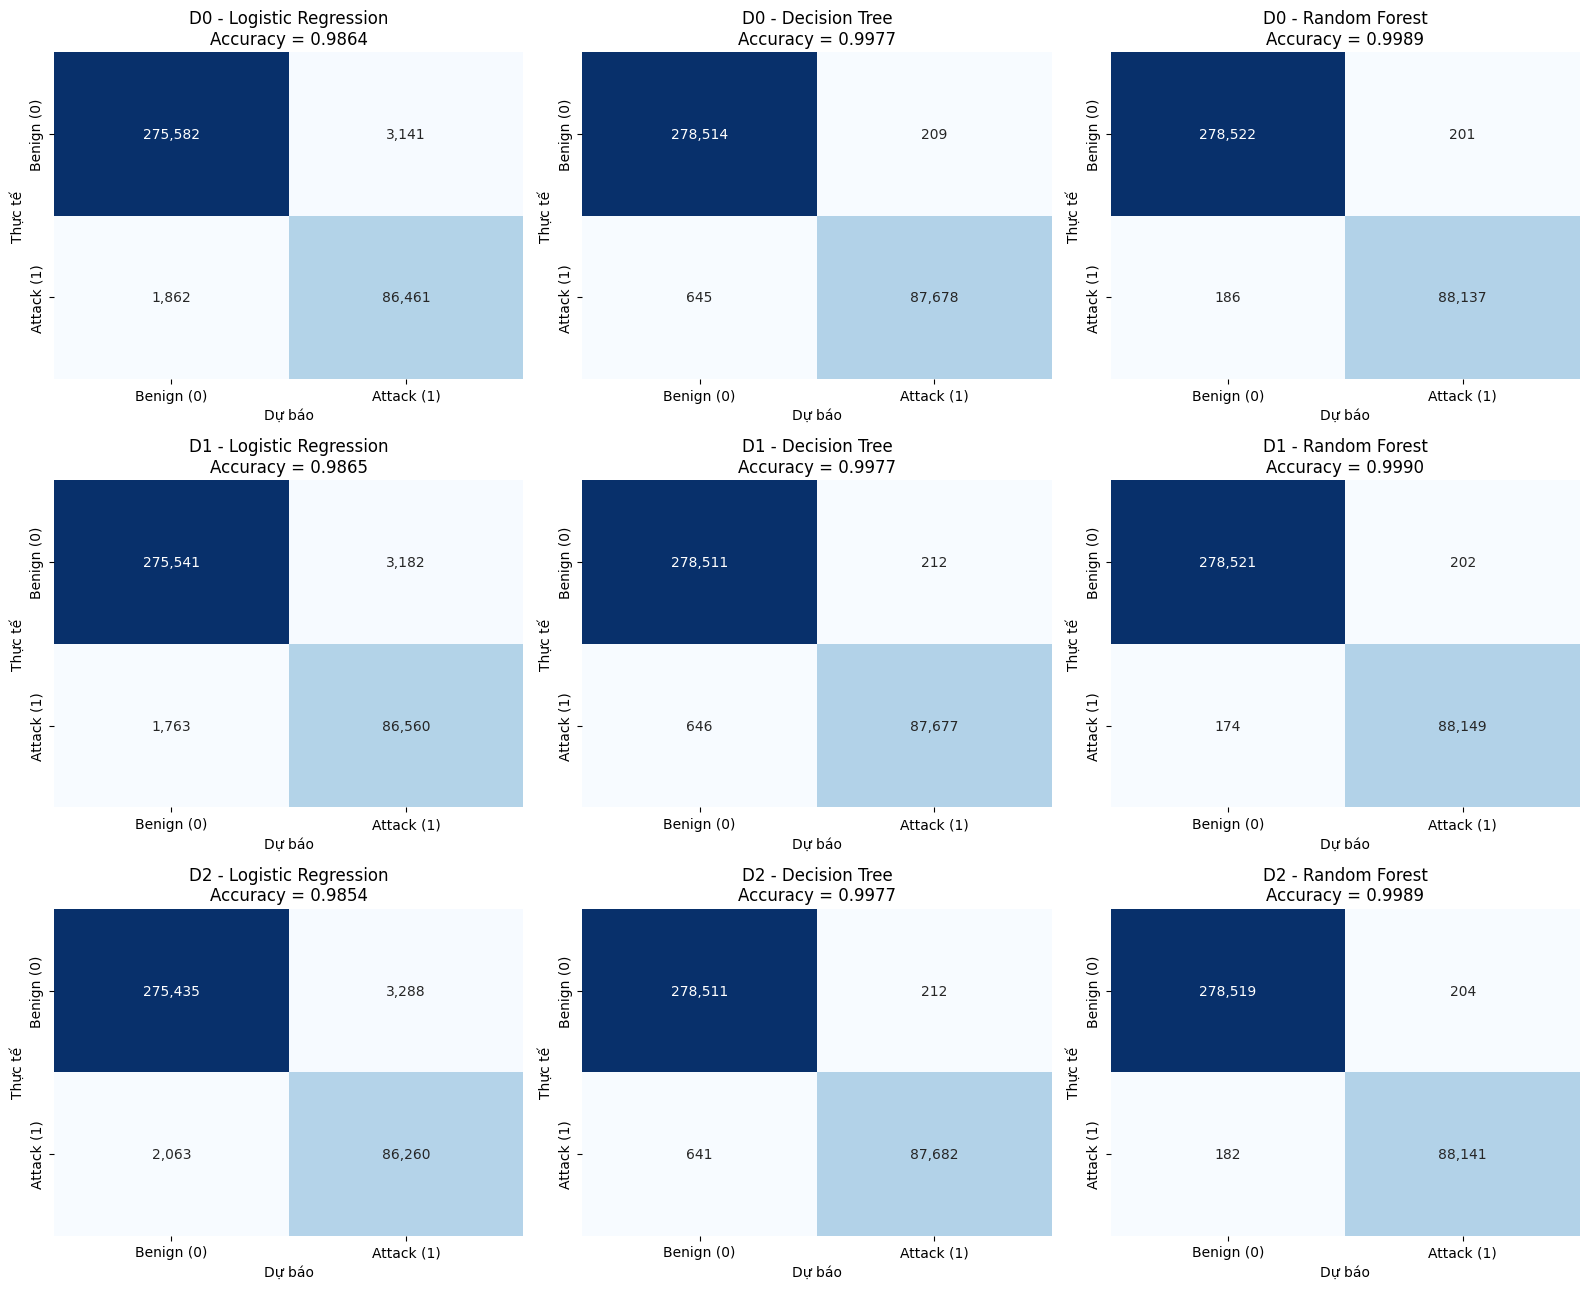

In [20]:
labels = ["Benign (0)", "Attack (1)"]
data_names = ["D0", "D1", "D2"]
model_names = list(build_models())

fig, axes = plt.subplots(
    len(data_names), len(model_names),
    figsize=(16, 13)
)

for i, data_name in enumerate(data_names):
    for j, model_name in enumerate(model_names):
        matrix = confusion_matrices[(data_name, model_name)]
        ax = axes[i, j]

        sns.heatmap(
            matrix,
            annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax
        )

        accuracy = np.trace(matrix) / matrix.sum()
        ax.set_title(f"{data_name} - {model_name}\nAccuracy = {accuracy:.4f}")
        ax.set_xlabel("Dự báo")
        ax.set_ylabel("Thực tế")

plt.tight_layout()
plt.savefig(output_dir / "05_confusion_matrix.png", dpi=120)
plt.show()

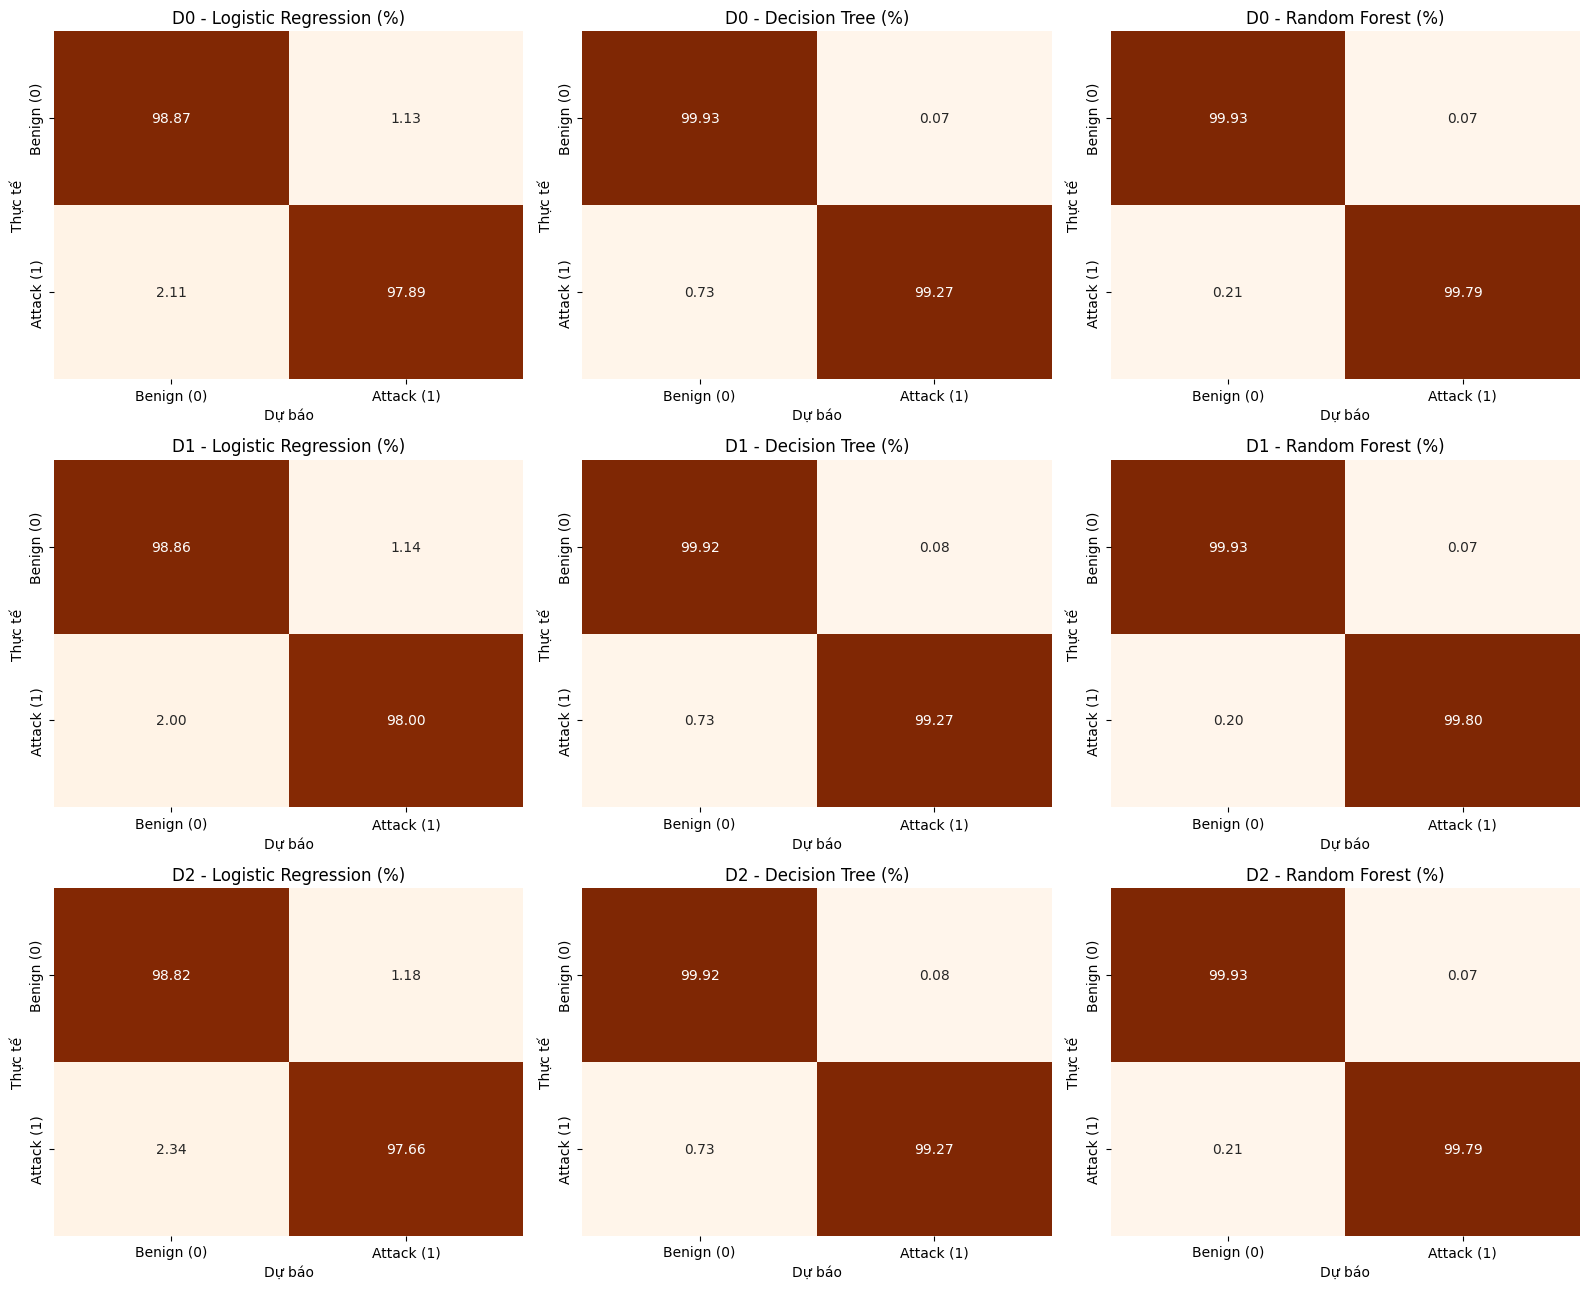

In [21]:
# Ma trận nhầm lẫn theo tỷ lệ phần trăm trên từng nhãn thật
fig, axes = plt.subplots(
    len(data_names), len(model_names),
    figsize=(16, 13)
)

for i, data_name in enumerate(data_names):
    for j, model_name in enumerate(model_names):
        matrix = confusion_matrices[(data_name, model_name)]
        percent = 100 * matrix / matrix.sum(axis=1, keepdims=True)
        ax = axes[i, j]

        sns.heatmap(
            percent,
            annot=True, fmt=".2f", cmap="Oranges", cbar=False,
            vmin=0, vmax=100,
            xticklabels=labels, yticklabels=labels, ax=ax
        )

        ax.set_title(f"{data_name} - {model_name} (%)")
        ax.set_xlabel("Dự báo")
        ax.set_ylabel("Thực tế")

plt.tight_layout()
plt.savefig(output_dir / "06_confusion_matrix_percent.png", dpi=120)
plt.show()

# So sánh trước và sau khi thêm luật
Thêm luật không chắc làm mô hình tốt hơn, kết quả bên dưới để nguyên không điều chỉnh.

In [22]:
acc = result_table.pivot(index="Mô hình", columns="Bộ dữ liệu", values="Accuracy")
f1 = result_table.pivot(index="Mô hình", columns="Bộ dữ liệu", values="F1-score")

effect_table = pd.DataFrame({
    "Accuracy D0": acc["D0"],
    "Accuracy D1": acc["D1"],
    "Accuracy D2": acc["D2"],
    "Chênh lệch Accuracy (D1 - D0)": acc["D1"] - acc["D0"],
    "Chênh lệch Accuracy (D2 - D0)": acc["D2"] - acc["D0"],
    "F1 D0": f1["D0"],
    "F1 D1": f1["D1"],
    "F1 D2": f1["D2"],
    "Chênh lệch F1 (D1 - D0)": f1["D1"] - f1["D0"],
    "Chênh lệch F1 (D2 - D0)": f1["D2"] - f1["D0"],
}).round(5)

effect_table.to_csv(output_dir / "07_d0_vs_d1_vs_d2.csv")

effect_table

,Accuracy D0,Accuracy D1,Accuracy D2,Chênh lệch Accuracy (D1 - D0),Chênh lệch Accuracy (D2 - D0),F1 D0,F1 D1,F1 D2,Chênh lệch F1 (D1 - D0),Chênh lệch F1 (D2 - D0)
Mô hình,,,,,,,,,,
Decision Tree,0.99767,0.99766,0.99768,-0.00001,0.00000,0.99515,0.99513,0.99516,-0.00002,0.00001
Logistic Regression,0.98637,0.98653,0.98542,0.00016,-0.00095,0.97188,0.97223,0.96992,0.00035,-0.00197
Random Forest,0.99895,0.99898,0.99895,0.00003,0.00000,0.99781,0.99787,0.99782,0.00006,0.00001


# Kết luận

In [23]:
best = result_table.sort_values(["F1-score", "Accuracy"], ascending=False).iloc[0]

print("1. Khai phá luật:")
print("   - Ba phương pháp chạy cùng ngưỡng: min_support =", MIN_SUPPORT,
      ", min_confidence =", MIN_CONFIDENCE)
print("   - Apriori và FP-Growth cho cùng tập mục phổ biến:", same_itemsets)
print("   - CHARM chỉ giữ tập mục đóng nên luật ít hơn:",
      len(rules_apriori), "luật (Apriori) so với", len(rules_charm), "luật (CHARM)")
print("   - Độ phủ chung của 3 luật:")
for method, coverage in coverage_all.items():
    print("       ", method, ":", round(100 * coverage, 2), "%")
print("   - Luật dùng tạo 3 thuộc tính mới cho D1:", chosen_method)
print()
print("2. Phân lớp:")
print("   - Mô hình tốt nhất:", best["Mô hình"], "trên bộ", best["Bộ dữ liệu"])
print("   - Accuracy:", round(best["Accuracy"], 4), "| F1-score:", round(best["F1-score"], 4))
print()
print("3. Tác động của 3 thuộc tính từ luật:")
for model_name in effect_table.index:
    print("   -", model_name,
          "| D1 - D0: Accuracy", effect_table.loc[model_name, "Chênh lệch Accuracy (D1 - D0)"],
          ", F1", effect_table.loc[model_name, "Chênh lệch F1 (D1 - D0)"])
    print("     ", " " * len(model_name),
          "| D2 - D0: Accuracy", effect_table.loc[model_name, "Chênh lệch Accuracy (D2 - D0)"],
          ", F1", effect_table.loc[model_name, "Chênh lệch F1 (D2 - D0)"])

1. Khai phá luật:
   - Ba phương pháp chạy cùng ngưỡng: min_support = 0.05 , min_confidence = 0.6
   - Apriori và FP-Growth cho cùng tập mục phổ biến: True
   - CHARM chỉ giữ tập mục đóng nên luật ít hơn: 78 luật (Apriori) so với 18 luật (CHARM)
   - Độ phủ chung của 3 luật:
        Apriori : 42.01 %
        FP-Growth : 42.01 %
        CHARM : 39.57 %
   - Luật dùng tạo 3 thuộc tính mới cho D1: Apriori

2. Phân lớp:
   - Mô hình tốt nhất: Random Forest trên bộ D1
   - Accuracy: 0.999 | F1-score: 0.9979

3. Tác động của 3 thuộc tính từ luật:
   - Decision Tree | D1 - D0: Accuracy -1e-05 , F1 -2e-05
                    | D2 - D0: Accuracy 0.0 , F1 1e-05
   - Logistic Regression | D1 - D0: Accuracy 0.00016 , F1 0.00035
                          | D2 - D0: Accuracy -0.00095 , F1 -0.00197
   - Random Forest | D1 - D0: Accuracy 3e-05 , F1 6e-05
                    | D2 - D0: Accuracy 0.0 , F1 1e-05
